# 02 — Analysis: who buys a policy, and how payment behaviour relates to it

Uses the cleaned data from `src/prep.py` (see `01_profiling.ipynb` for every cleaning decision).

- **Policy** = `label`: rejected / bought PA (personal accident) / bought life.
- **Payment** = `easypymt_last_30d`: bank payments in the 30 days *before* the offer (not premium).

Because only 1.2% accept, everything is expressed as an **acceptance rate** (% of customers offered), split into **PA rate** and **life rate**.
Differences are checked with a chi-square test, and the strength of each factor with Cramér's V (0 = no association, 1 = perfect).
At the end, a logistic regression checks which factors still matter once the others are held constant.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from src import prep

pd.set_option("display.max_columns", 50, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"

df, _ = prep.load_clean()
print(f"{len(df):,} customers after cleaning")

214,053 customers after cleaning


## 1. Headline numbers

In [2]:
kpi = pd.Series({
    "customers offered": len(df),
    "policies sold": int(df["accepted"].sum()),
    "  PA policies": int(df["bought_pa"].sum()),
    "  life policies": int(df["bought_life"].sum()),
    "acceptance rate %": round(df["accepted"].mean() * 100, 2),
    "  PA rate %": round(df["bought_pa"].mean() * 100, 2),
    "  life rate %": round(df["bought_life"].mean() * 100, 2),
    "PA share of policies sold %": round(df["bought_pa"].sum() / df["accepted"].sum() * 100, 1),
    "median payment last 30d (baht)": df["easypymt_last_30d"].median(),
    "customers with no payment %": round((df["easypymt_last_30d"] == 0).mean() * 100, 1),
})
kpi.to_frame("value")

,value
customers offered,214053.00
policies sold,2622.00
PA policies,1634.00
life policies,988.00
acceptance rate %,1.22
PA rate %,0.76
life rate %,0.46
PA share of policies sold %,62.30
median payment last 30d (baht),373.00
customers with no payment %,21.30


214,053 customers were offered a policy and **2,622 bought one (1.22%)**. PA is the bigger product: 1,634 policies (62% of sales, 0.76% rate) against 988 life (0.46%).
The typical customer paid 373 baht from their account in the 30 days before the offer, and 1 in 5 paid nothing.

## 2. Which factors are associated with buying?

In [3]:
def cramers_v(table):
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    return chi2, p, np.sqrt(chi2 / (n * (min(table.shape) - 1)))

factors = ["account_active", "payment_band", "age_band", "customer_segment", "income_band", "main_occupation", "gender",
           "marital", "scb_payroll", "have_cc", "have_acc_planet", "has_children", "campaign_month"]
rows = []
for f in factors:
    t = pd.crosstab(df[f], df["response"])
    chi2, p, v = cramers_v(t)
    r = prep.rates_by(df, f)
    rows.append({"factor": f, "groups": len(t), "chi2_p_value": p, "cramers_v": round(v, 4),
                 "accept_rate_range_%": f"{r['accept_rate'].min():.2f} - {r['accept_rate'].max():.2f}"})
assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
assoc["significant (p<0.001)"] = assoc["chi2_p_value"] < 0.001
assoc

,factor,groups,chi2_p_value,cramers_v,accept_rate_range_%,significant (p<0.001)
0,account_active,2,1.137783e-155,0.0578,0.70 - 1.75,True
1,campaign_month,12,1.282853e-66,0.0297,0.82 - 1.95,True
2,payment_band,6,1.936526e-44,0.0234,0.62 - 1.49,True
3,age_band,4,7.453775e-42,0.0220,0.96 - 1.75,True
4,gender,2,1.571237e-22,0.0217,1.07 - 1.42,True
5,have_cc,2,3.875142e-18,0.0194,0.97 - 1.25,True
6,main_occupation,10,1.079753e-13,0.0154,0.00 - 2.05,True
7,customer_segment,3,4.802035e-17,0.0139,1.19 - 1.26,True
8,income_band,5,2.240007e-12,0.0130,1.16 - 1.31,True
9,marital,4,1.001904e-08,0.0107,0.99 - 1.32,True


**Every factor except payroll and children is significant (p < 0.001), but every effect is small** (Cramér's V ≤ 0.06). With 214k rows, even tiny differences pass a significance test, so the useful question is *how big* the difference is, not *whether* it exists.

The strongest single factor is **account activity** (V = 0.058), then campaign month, payment and age. Segment and income, the usual targeting fields, are among the weakest.

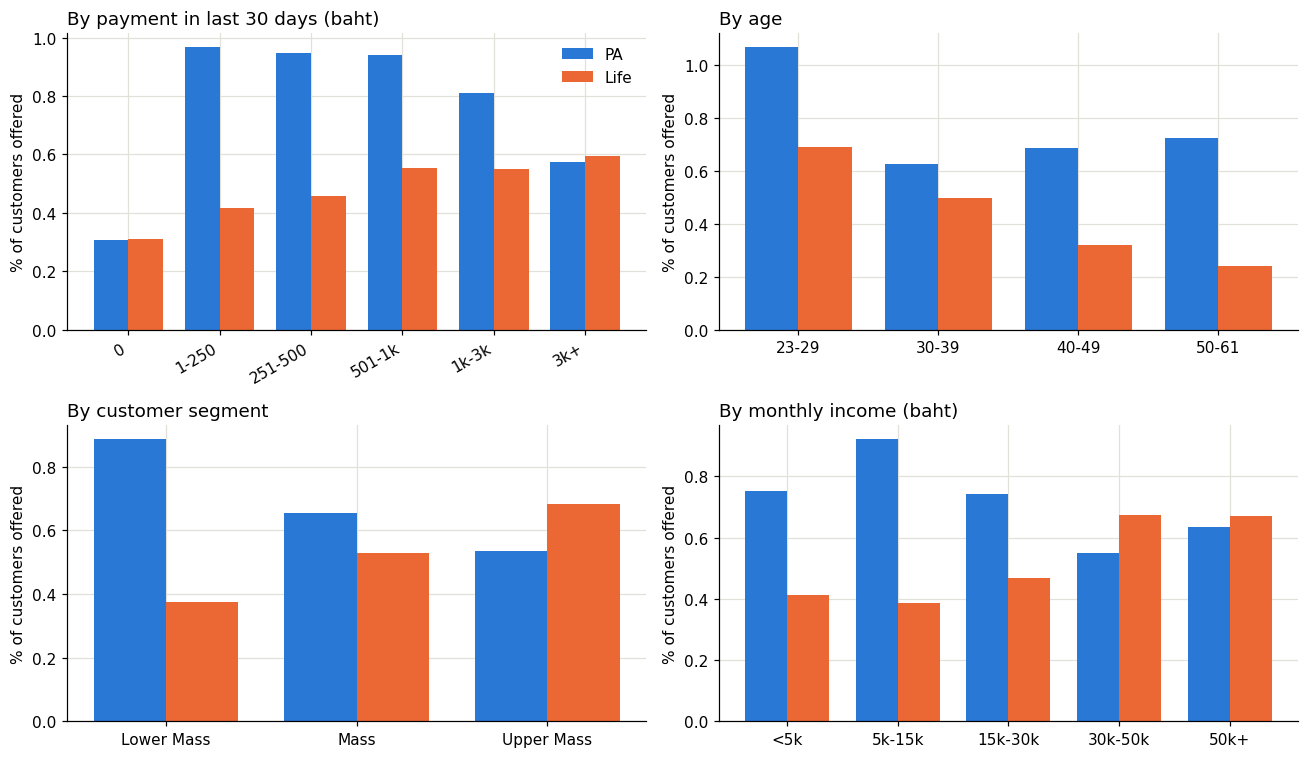

In [4]:
def plot_rates(col, title, order=None, ax=None, min_n=500):
    r = prep.rates_by(df, col)
    r = r[r["customers"] >= min_n]
    if order is not None:
        r = r.reindex([o for o in order if o in r.index])
    ax = ax or plt.gca()
    x = np.arange(len(r)); w = 0.38
    ax.bar(x - w/2, r["pa_rate"], w, color=BLUE, label="PA")
    ax.bar(x + w/2, r["life_rate"], w, color=ORANGE, label="Life")
    ax.set_xticks(x); ax.set_xticklabels(r.index, rotation=30 if len(r) > 5 else 0, ha="right" if len(r) > 5 else "center")
    ax.set_ylabel("% of customers offered"); ax.set_title(title, loc="left")
    return r

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_rates("payment_band", "By payment in last 30 days (baht)", prep.PAYMENT_LABELS, axes[0, 0])
plot_rates("age_band", "By age", prep.AGE_LABELS, axes[0, 1])
plot_rates("customer_segment", "By customer segment", prep.SEGMENTS, axes[1, 0])
plot_rates("income_band", "By monthly income (baht)", prep.INCOME_LABELS, axes[1, 1])
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Payment behaviour (`easypymt_last_30d`)

In [5]:
pay = prep.rates_by(df, "payment_band").reindex(prep.PAYMENT_LABELS)
pay["share_of_customers_%"] = (pay["customers"] / pay["customers"].sum() * 100).round(1)
pay["lift_vs_avg"] = (pay["accept_rate"] / (df["accepted"].mean() * 100)).round(2)
pay

,customers,pa_rate,life_rate,accept_rate,share_of_customers_%,lift_vs_avg
payment_band,,,,,,
0,45616,0.307,0.309,0.616,21.4,0.50
1-250,40007,0.967,0.417,1.385,18.7,1.13
251-500,39492,0.947,0.456,1.403,18.5,1.15
501-1k,39197,0.939,0.554,1.492,18.4,1.22
1k-3k,34487,0.809,0.551,1.360,16.1,1.11
3k+,14793,0.575,0.595,1.169,6.9,0.95


In [6]:
fin = df[df["has_financials"]]
summary = fin.groupby("response")[["easypymt_last_30d", "savacc_bal", "avg_savaccbal_30d", "income", "inflow30d",
                                   "outflow30d", "maxosdc_last_30d", "mob"]].median().T
summary.columns.name = "median by response"
display(summary.round(0))

rej = fin.loc[fin["label"] == 0, "easypymt_last_30d"]
for lab, name in [(1, "PA"), (2, "Life")]:
    buy = fin.loc[fin["label"] == lab, "easypymt_last_30d"]
    u, p = stats.mannwhitneyu(buy, rej, alternative="two-sided")
    print(f"{name} buyers vs rejecters - payment Mann-Whitney U p = {p:.2e}; "
          f"zero-payment share {(buy == 0).mean():.1%} vs {(rej == 0).mean():.1%}")

median by response,Life,PA (personal accident),Rejected
easypymt_last_30d,507.0,436.0,372.0
savacc_bal,1436.0,896.0,800.0
avg_savaccbal_30d,1333.0,1145.0,991.0
income,15140.0,11325.0,12250.0
inflow30d,2.0,14792.0,0.0
outflow30d,218.0,16093.0,0.0
maxosdc_last_30d,0.0,0.0,0.0
mob,54.0,39.0,40.0


PA buyers vs rejecters - payment Mann-Whitney U p = 1.31e-09; zero-payment share 8.6% vs 21.5%
Life buyers vs rejecters - payment Mann-Whitney U p = 2.54e-11; zero-payment share 14.3% vs 21.5%


paid,no payment,paid something
customer_segment,,
Lower Mass,0.64,1.48
Mass,0.60,1.31
Upper Mass,0.25,1.33


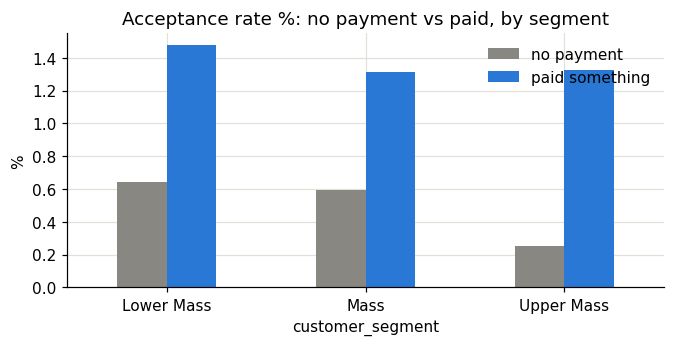

In [7]:
paid = df[df["has_financials"]].assign(paid=lambda d: np.where(d["easypymt_last_30d"] > 0, "paid something", "no payment"))
t = paid.pivot_table(index="customer_segment", columns="paid", values="accepted", aggfunc="mean", observed=True) * 100
display(t.round(2))
t.plot.bar(color=[GREY, BLUE], figsize=(7, 3), rot=0, title="Acceptance rate %: no payment vs paid, by segment")
plt.ylabel("%"); plt.legend(frameon=False); plt.show()

### Account activity

The medians above show something stronger than payment: the typical PA buyer had ~15k baht flowing in and out of their account in the last 30 days, while the typical rejecter had **none**.
`account_active` = any inflow or outflow in the last 30 days (`src/prep.py`).

In [8]:
act = prep.rates_by(fin, "account_active")
display(act)
fin2 = fin.assign(paid=np.where(fin["easypymt_last_30d"] > 0, "paid", "no payment"))
combo = fin2.pivot_table(index="account_active", columns="paid", values="bought_pa", aggfunc="mean") * 100
print("PA rate % by account activity x payment:"); display(combo.round(2))
print("share of buyers with an active account: PA", f"{fin.loc[fin.label == 1, 'account_active'].eq('active').mean():.0%}",
      "| life", f"{fin.loc[fin.label == 2, 'account_active'].eq('active').mean():.0%}",
      "| rejected", f"{fin.loc[fin.label == 0, 'account_active'].eq('active').mean():.0%}")

,customers,pa_rate,life_rate,accept_rate
account_active,,,,
active,106762,1.267,0.481,1.748
dormant,106830,0.262,0.440,0.702


PA rate % by account activity x payment:


paid,no payment,paid
account_active,,
active,0.79,1.34
dormant,0.09,0.33


share of buyers with an active account: PA 83% | life 52% | rejected 50%


**This is the strongest finding in the data, and it is about PA only.**
- PA rate is **1.27% for active accounts vs 0.26% for dormant ones: almost 5×.** 83% of PA buyers had an active account, against 50% of rejecters.
- Life is flat (0.48% vs 0.44%). Account activity says nothing about who buys life.
- Activity and payment add up. Dormant accounts that also made no payment buy PA at **0.09%**, about one-eighth of the average.

**Caution.** This is observational data. A likely explanation is the *channel*: if PA was offered in the banking app, only active users would see it. I can't tell from this file, and it changes the recommendation (the fix could be "offer PA where dormant customers will see it" rather than "stop offering").

**Payment behaviour matters, and mostly as "any payment vs none".**
- Customers who made no payment in the last 30 days accept at **0.62%**, half the average. Every band of paying customers sits at 1.2–1.5%.
- **PA** peaks at small payments (1–1,000 baht, ~0.95%) and falls for big payers (0.58% at 3k+).
- **Life** rises steadily with payment size, from 0.31% (no payment) to 0.60% (3k+).
- Buyers of both products paid more than rejecters (Mann-Whitney p < 1e-8), and far fewer of them had zero payments (PA 8.6%, life 14.3%, rejecters 21.5%).
- The no-payment gap holds in every segment, so it is not just segment in disguise.

## 4. Who buys PA vs life

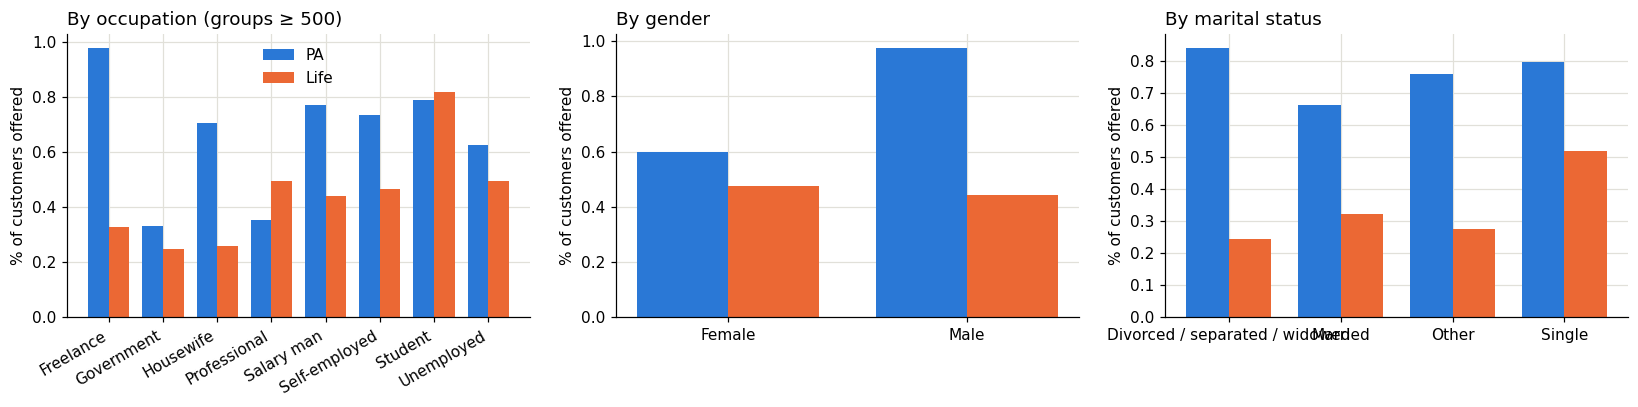

customers  pa_rate  life_rate  accept_rate
scb_payroll     N       170285    0.739      0.441        1.180
                Y        43764    0.855      0.542        1.396
have_cc         N       192622    0.812      0.441        1.253
                Y        21427    0.317      0.649        0.966
have_acc_planet N       210167    0.774      0.458        1.232
                Y         3425    0.204      0.584        0.788
has_children    0.0     207257    0.762      0.469        1.230
                1.0       6790    0.795      0.250        1.046

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
plot_rates("main_occupation", "By occupation (groups ≥ 500)", None, axes[0])
plot_rates("gender", "By gender", None, axes[1])
plot_rates("marital", "By marital status", None, axes[2])
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

flags = pd.concat({f: prep.rates_by(df, f) for f in ["scb_payroll", "have_cc", "have_acc_planet", "has_children"]})
flags

**PA and life attract different customers.**
- **Men** buy PA at 0.98% vs 0.60% for women; life is the same for both.
- **Credit-card holders** buy *less* PA (0.32% vs 0.81%) but *more* life (0.65% vs 0.44%). **Planet travel-card holders** show the same pattern even more strongly (PA 0.20%). One hypothesis: these products already include accident or travel cover, so a separate PA policy adds little.
- **Students** and **Freelance** workers have the highest acceptance among large occupation groups; **Government** employees the lowest (they have state welfare cover).
- **Singles** buy life more often than married customers (0.52% vs 0.32%).
- Payroll and children: no meaningful difference.

## 5. Campaign month

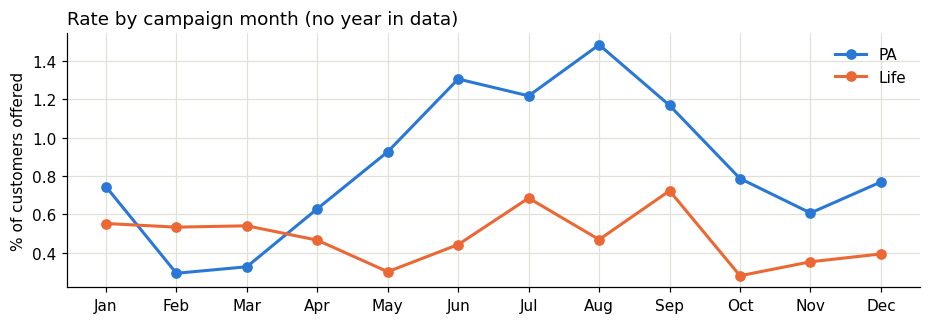

Spearman correlation, customers offered vs PA rate across months: -0.62 (p = 0.033)


,customers,pa_rate,life_rate,accept_rate
campaign_month,,,,
Jan,22282,0.745,0.552,1.297
Feb,21586,0.292,0.533,0.825
Mar,21493,0.326,0.540,0.865
Apr,21933,0.629,0.465,1.094
May,14672,0.927,0.300,1.227
Jun,10179,1.307,0.442,1.749
Jul,11242,1.219,0.685,1.904
Aug,11107,1.486,0.468,1.954
Sep,11210,1.169,0.723,1.891


In [10]:
mon = prep.rates_by(df, "campaign_month")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mon.index.astype(str), mon["pa_rate"], marker="o", color=BLUE, lw=2, label="PA")
ax.plot(mon.index.astype(str), mon["life_rate"], marker="o", color=ORANGE, lw=2, label="Life")
ax.set_ylabel("% of customers offered"); ax.legend(frameon=False); ax.set_title("Rate by campaign month (no year in data)", loc="left")
plt.show()
corr = stats.spearmanr(mon["customers"], mon["pa_rate"])
print(f"Spearman correlation, customers offered vs PA rate across months: {corr.statistic:.2f} (p = {corr.pvalue:.3f})")
mon

Jun–Sep had **half the volume** (~11k offers vs ~22k) but **the highest acceptance** (1.75–1.96% vs 0.8–1.3%). Across months, more offers go with a lower PA rate (Spearman −0.62, p = 0.03).
Two possible reasons: smaller campaigns were better targeted, or the file mixes two campaign waves. Without a year or campaign ID I can't tell, so I report it as an open question rather than as seasonality.

## 6. Which factors matter once the others are held constant?

Logistic regression, one model per product (bought PA vs not, bought life vs not), on customers with complete data.
Output is an **odds ratio**: 1.5 means 50% higher odds than the reference group, 0.5 means half.
This is a check on the one-factor-at-a-time charts above (e.g. is the age effect really income in disguise?), not a production model.

In [11]:
m = df.dropna(subset=["account_active", "age_band", "customer_segment", "income_band", "payment_band", "marital",
                      "scb_payroll", "have_cc", "have_acc_planet", "main_occupation"]).copy()
m["occupation"] = m["main_occupation"].where(m["main_occupation"].isin(
    ["Salary man", "Self-employed", "Freelance", "Student", "Government"]), "Other")
for c in ["age_band", "customer_segment", "income_band", "payment_band"]:
    m[c] = m[c].astype(str)
rhs = ("C(account_active, Treatment('dormant')) + C(payment_band, Treatment('0')) + C(age_band, Treatment('30-39')) + C(customer_segment, Treatment('Mass'))"
       " + C(income_band, Treatment('15k-30k')) + C(gender) + C(marital, Treatment('Single'))"
       " + C(occupation, Treatment('Salary man')) + C(scb_payroll) + C(have_cc) + C(have_acc_planet)")

def odds_table(target):
    fit = smf.logit(f"{target} ~ {rhs}", data=m).fit(disp=0)
    ci = np.exp(fit.conf_int())
    out = pd.DataFrame({"odds_ratio": np.exp(fit.params), "ci_low": ci[0], "ci_high": ci[1], "p_value": fit.pvalues})
    out.index = (out.index.str.replace(r"C\((\w+)(?:, Treatment\('[^']*'\))?\)\[T\.", r"\1 = ", regex=True)
                          .str.rstrip("]"))
    return out.drop("Intercept").round(3), fit

print(f"{len(m):,} customers with complete data")
pa_or, pa_fit = odds_table("bought_pa")
life_or, life_fit = odds_table("bought_life")
both = pa_or[["odds_ratio", "p_value"]].join(life_or[["odds_ratio", "p_value"]], lsuffix="_PA", rsuffix="_life")
print(f"pseudo R2: PA {pa_fit.prsquared:.3f}, life {life_fit.prsquared:.3f}")
both

210,458 customers with complete data


pseudo R2: PA 0.061, life 0.020


,odds_ratio_PA,p_value_PA,odds_ratio_life,p_value_life
account_active = active,4.221,0.000,1.037,0.579
payment_band = 1-250,2.023,0.000,1.052,0.671
payment_band = 1k-3k,2.412,0.000,1.493,0.001
payment_band = 251-500,2.299,0.000,1.168,0.187
payment_band = 3k+,1.912,0.000,1.559,0.002
payment_band = 501-1k,2.550,0.000,1.455,0.001
age_band = 23-29,1.573,0.000,1.369,0.000
age_band = 40-49,1.133,0.081,0.653,0.000
age_band = 50-61,1.234,0.016,0.515,0.000
customer_segment = Lower Mass,1.292,0.000,0.780,0.009


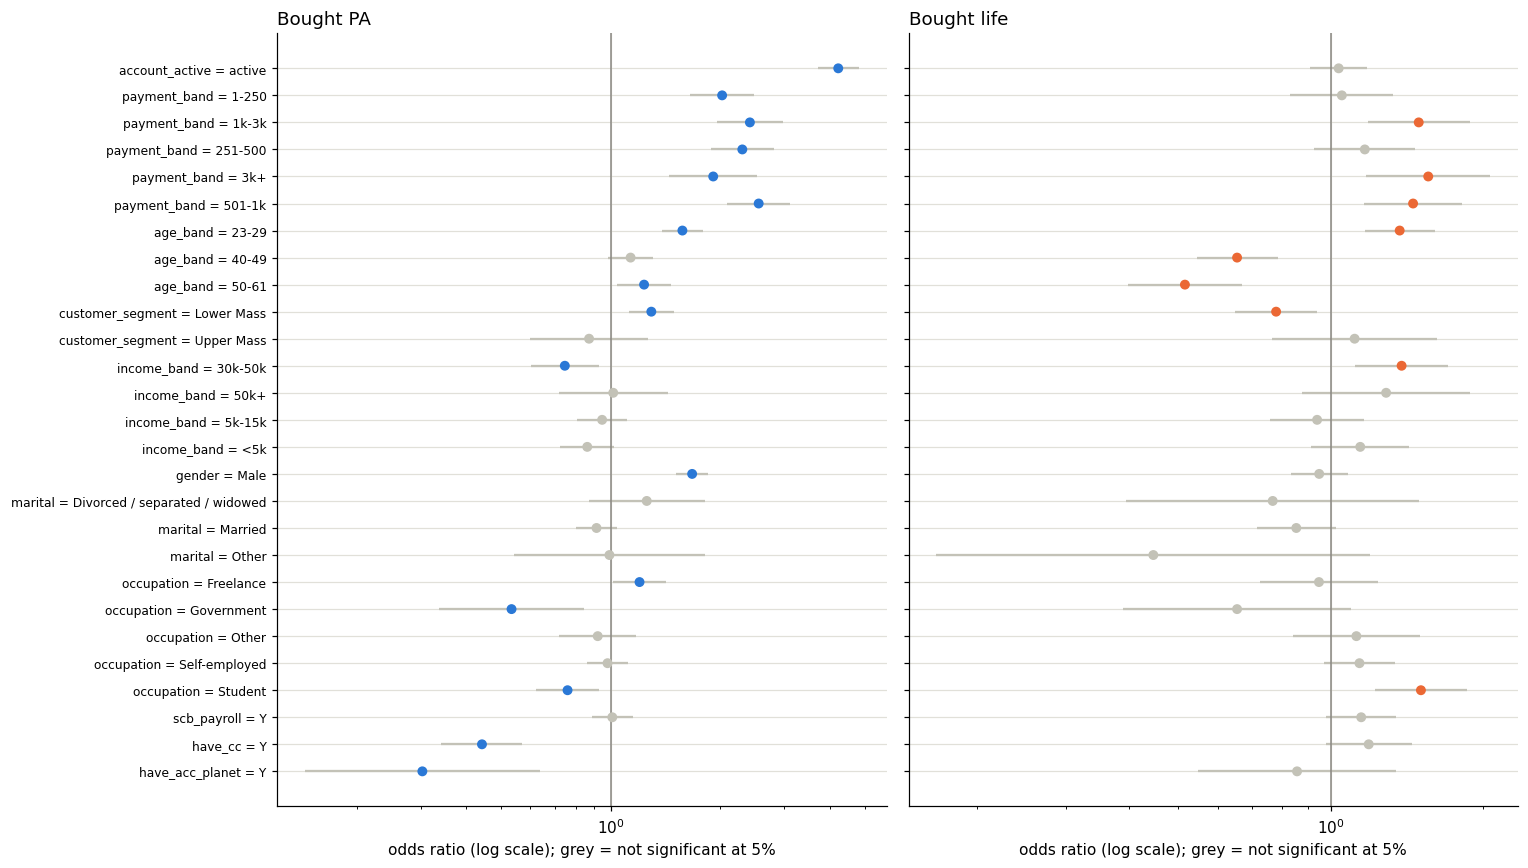

In [12]:
def forest(tbl, title, ax, color):
    t = tbl.iloc[::-1]
    y = np.arange(len(t))
    sig = t["p_value"] < 0.05
    ax.errorbar(t["odds_ratio"], y, xerr=[t["odds_ratio"] - t["ci_low"], t["ci_high"] - t["odds_ratio"]],
                fmt="none", ecolor="#c3c2b7", lw=1.5)
    ax.scatter(t["odds_ratio"], y, color=np.where(sig, color, "#c3c2b7"), s=30, zorder=3)
    ax.axvline(1, color=GREY, lw=1); ax.set_xscale("log")
    ax.set_yticks(y); ax.set_yticklabels(t.index, fontsize=8); ax.set_title(title, loc="left")
    ax.set_xlabel("odds ratio (log scale); grey = not significant at 5%")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
forest(pa_or, "Bought PA", axes[0], BLUE)
forest(life_or, "Bought life", axes[1], ORANGE)
plt.tight_layout(); plt.show()

**Holding the other factors constant, the picture survives:**

| Factor | PA odds ratio | Life odds ratio |
|---|---|---|
| Active account (vs dormant) | **4.2** | 1.0 (n.s.) |
| Any payment (vs none) | **1.9–2.5** | 1.0–1.6 (only ≥ 501 baht significant) |
| Age 23–29 (vs 30–39) | **1.6** | **1.4** |
| Age 50–61 (vs 30–39) | 1.2 | **0.5** |
| Male | **1.7** | 0.95 (n.s.) |
| Has credit card | **0.44** | 1.2 (n.s.) |
| Has Planet travel card | **0.30** | 0.86 (n.s.) |
| Lower Mass (vs Mass) | **1.3** | **0.78** |
| Income 30–50k (vs 15–30k) | **0.75** | **1.4** |
| Student (vs salary man) | **0.76** | **1.5** |

(n.s. = not significant at 5%.)

Two checks on the earlier charts:
- **Age is not income in disguise.** Young customers buy more of both products even at the same income and segment.
- **Payment for PA is partly account activity.** The payment odds ratios drop from ~3 to ~2 once activity is added, but they stay significant.

Pseudo R² is low (PA 0.06, life 0.02): these fields explain only a small part of who buys. A real targeting model would need richer behaviour data (app usage, product holdings, past claims).

## 7. What would simple targeting change?

A rule anyone can apply without a model: **skip customers with a dormant account and no payments in the last 30 days**.

In [13]:
f = df[df["has_financials"]]
skip = (f["account_active"] == "dormant") & (f["easypymt_last_30d"] == 0)
keep = f[~skip]
res = pd.DataFrame({
    "offers": [len(f), len(keep)],
    "PA sold": [f["bought_pa"].sum(), keep["bought_pa"].sum()],
    "life sold": [f["bought_life"].sum(), keep["bought_life"].sum()],
}, index=["offer everyone", "skip dormant + no payment"])
res["PA rate %"] = (res["PA sold"] / res["offers"] * 100).round(3)
res["life rate %"] = (res["life sold"] / res["offers"] * 100).round(3)
display(res)
print(f"offers cut: {skip.mean():.1%} | PA sales lost: {1 - res.iloc[1]['PA sold'] / res.iloc[0]['PA sold']:.1%}"
      f" | life sales lost: {1 - res.iloc[1]['life sold'] / res.iloc[0]['life sold']:.1%}")

,offers,PA sold,life sold,PA rate %,life rate %
offer everyone,213592,1633,983,0.765,0.460
skip dormant + no payment,181971,1603,893,0.881,0.491


offers cut: 14.8% | PA sales lost: 1.8% | life sales lost: 9.2%


Skipping the dormant, no-payment group (15% of the base) **loses only 1.8% of PA sales**, and PA rate rises from 0.77% to 0.88%. It costs **9% of life sales**, though, because life buyers don't depend on activity.

So a sensible rule is: **offer PA to active customers only; keep offering life to everyone**, or send dormant customers a life-only offer.

## Key findings

1. **Conversion is low and the effects are modest.** 1.22% overall (PA 0.76%, life 0.46%). The best simple segments reach about 2×, not 10×.
2. **PA is an "active banker" product.** Active account → ~5× the PA rate (odds ratio 4.2 after controls). Any payment in the last 30 days → about 2× more.
3. **Life is a "young and somewhat better-off" product.** Ages 23–29, students, income 30–50k, larger payments. Account activity doesn't matter. Over-50s buy life at half the rate.
4. **Card holders swap PA for life.** Credit-card and Planet travel-card holders rarely buy PA but buy life as often or more, possibly because the cards already include accident or travel cover.
5. **Smaller campaign months converted better** (Jun–Sep). Worth checking with the campaign team whether targeting changed.

## Recommendations
- Route PA offers to customers with an active account; give dormant customers a life-only offer or a channel they actually use.
- Pitch life to the under-30s and to students and early-career earners. De-prioritise life for over-50s, or offer a product built for that age.
- For card holders, lead with life, not PA.
- Fix the data: re-extract the 15-day flow columns, add a campaign ID and year, add the premium and policy status so revenue can be measured, and add a customer ID so duplicates can be resolved.

## Limitations
- **Observational data.** The offer channel and message are unknown, so these are associations, not causes.
- **No premium column.** "Payment" here is pre-offer bank behaviour, so I cannot measure revenue or premium collection.
- **No year, no campaign ID.** Month differences may be different waves of the campaign, not seasonality.